# Submission Akhir: Multivariate Multi-Horizon Time Series Forecasting
**Nama Pengembang**: Muhammad Akhtar Ariq
**Kelas**: Deep Learning Terapan untuk Time Series (DLTM)

Proyek ini bertujuan untuk membangun model peramalan deret waktu multivariat multi-horizon menggunakan arsitektur deep learning berbasis LSTM. Kami membandingkan tiga model:
1. **Baseline LSTM**: Model benchmark menggunakan Custom Dense layer.
2. **Seq2Seq LSTM (Encoder-Decoder)**: Model sequence-to-sequence dengan pendekatan Teacher Forcing selama training.
3. **Best Seq2Seq LSTM (Advanced)**: Model sequence-to-sequence yang dioptimalkan dengan Bidirectional LSTM dan stacked layers.


In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, LSTM, Dense, Reshape, RepeatVector, TimeDistributed, Bidirectional, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print('TensorFlow Version:', tf.__version__)
print('GPU Available:', tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0


GPU Available: []


Shape dataset: (53150, 7)
Kolom yang tersedia: ['Date', 'Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']
Rentang Tanggal: 2017-09-21 09:00:00 hingga 2023-10-19 23:00:00


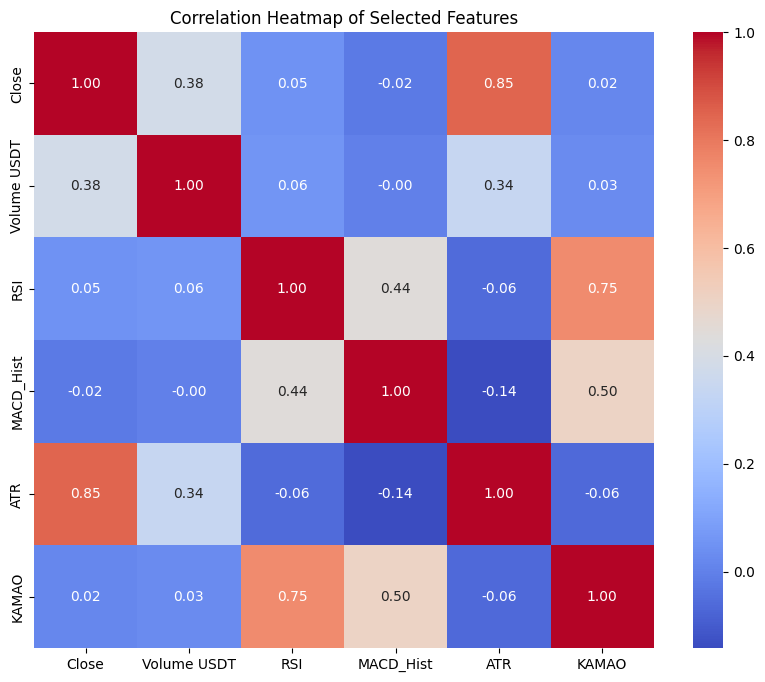

Jumlah missing values:
Date           0
Close          0
Volume USDT    0
RSI            0
MACD_Hist      0
ATR            0
KAMAO          0
dtype: int64
                 Date    Close    Volume USDT        RSI  MACD_Hist  \
0 2017-09-21 09:00:00  3860.00   74434.891166  49.192454 -48.279697   
1 2017-09-21 10:00:00  3871.48   44687.318944  49.233202 -47.780476   
2 2017-09-21 11:00:00  3864.95   80546.171672  49.210685 -47.308061   
3 2017-09-21 12:00:00  3858.08   90331.531390  49.186948 -46.863233   
4 2017-09-21 13:00:00  3856.67  103405.818040  49.182064 -46.425379   

         ATR     KAMAO  
0  88.054720  2.495591  
1  87.996283  2.616710  
2  87.897128  2.532239  
3  87.720856  2.447245  
4  87.578086  2.424654  


In [2]:
# Memuat dataset
csv_path = 'Bitcoin3.csv'
if not os.path.exists(csv_path):
    csv_path = os.path.join('..', 'Bitcoin3.csv')

df = pd.read_csv(csv_path)
print('Shape dataset:', df.shape)
print('Kolom yang tersedia:', df.columns.tolist())

# Parsing Tanggal
df['Date'] = pd.to_datetime(df['Date'], format='mixed')
df = df.sort_values('Date').reset_index(drop=True)

print('Rentang Tanggal:', df['Date'].min(), 'hingga', df['Date'].max())

# Eksplorasi Data Analisis - Heatmap Korelasi (Kriteria 1)
feature_cols = ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']
plt.figure(figsize=(10, 8))
correlation_matrix = df[feature_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Selected Features')
plt.savefig('correlation_heatmap.png')
plt.show()

print('Jumlah missing values:')
print(df.isnull().sum())
print(df.head())

In [3]:
# Menentukan fitur dan target
feature_cols = ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']
target_col = 'Close'

# Membagi dataset secara kronologis (Chronological Split)
n_samples = len(df)
train_end = int(n_samples * 0.8)
val_end = train_end + int(n_samples * 0.1)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

print(f'Jumlah sampel: Train={len(train_df)} (80%), Val={len(val_df)} (10%), Test={len(test_df)} (10%)')

# Scaling terpisah untuk fitur dan target
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

# Fit scaler hanya pada training set
feature_scaler.fit(train_df[feature_cols])
target_scaler.fit(train_df[[target_col]])

# Transformasi data
scaled_train_features = feature_scaler.transform(train_df[feature_cols])
scaled_train_targets = target_scaler.transform(train_df[[target_col]])

scaled_val_features = feature_scaler.transform(val_df[feature_cols])
scaled_val_targets = target_scaler.transform(val_df[[target_col]])

scaled_test_features = feature_scaler.transform(test_df[feature_cols])
scaled_test_targets = target_scaler.transform(test_df[[target_col]])

Jumlah sampel: Train=42520 (80%), Val=5315 (10%), Test=5315 (10%)


In [4]:
def create_sliding_windows(features, targets, seq_len, horizon):
    X, y = [], []
    for i in range(len(features) - seq_len - horizon + 1):
        X.append(features[i : i + seq_len])
        y.append(targets[i + seq_len : i + seq_len + horizon])
    return np.array(X), np.array(y)

seq_len = 24
horizon = 24

X_train, y_train = create_sliding_windows(scaled_train_features, scaled_train_targets, seq_len, horizon)
X_val, y_val = create_sliding_windows(scaled_val_features, scaled_val_targets, seq_len, horizon)
X_test, y_test = create_sliding_windows(scaled_test_features, scaled_test_targets, seq_len, horizon)

print('Bentuk dataset setelah windowing:')
print(f' - X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f' - X_val: {X_val.shape}, y_val: {y_val.shape}')
print(f' - X_test: {X_test.shape}, y_test: {y_test.shape}')

Bentuk dataset setelah windowing:
 - X_train: (42473, 24, 6), y_train: (42473, 24, 1)
 - X_val: (5268, 24, 6), y_val: (5268, 24, 1)
 - X_test: (5268, 24, 6), y_test: (5268, 24, 1)


In [5]:
# Membuat ulang Dense Layer menggunakan Custom Layer (Kriteria 2)
@tf.keras.utils.register_keras_serializable(package='CustomLayers')
class CustomDense(tf.keras.layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super(CustomDense, self).__init__(**kwargs)
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        self.w = self.add_weight(
            shape=(input_dim, self.units),
            initializer='glorot_uniform',
            trainable=True,
            name='weight'
        )
        self.b = self.add_weight(
            shape=(self.units,),
            initializer='zeros',
            trainable=True,
            name='bias'
        )
        super(CustomDense, self).build(input_shape)

    def call(self, inputs):
        output = tf.matmul(inputs, self.w) + self.b
        if self.activation is not None:
            output = self.activation(output)
        return output

    def compute_output_shape(self, input_shape):
        input_shape = list(input_shape)
        input_shape[-1] = self.units
        return tuple(input_shape)

    def get_config(self):
        config = super(CustomDense, self).get_config()
        config.update({
            'units': self.units,
            'activation': tf.keras.activations.serialize(self.activation)
        })
        return config

print('Class CustomDense berhasil dibuat.')

Class CustomDense berhasil dibuat.


In [6]:
# Membuat Custom Training Loop dengan tf.GradientTape() & tf.function (Kriteria 3)
def train_model_custom_loop(model, train_data, val_data, epochs=8, batch_size=128, is_seq2seq=False):
    optimizer = tf.keras.optimizers.Adam()
    loss_fn = tf.keras.losses.MeanSquaredError()

    X_train, y_train = train_data
    X_val, y_val = val_data

    num_train_samples = X_train.shape[0]
    num_val_samples = X_val.shape[0]

    print(f'Melatih {model.name} dengan Custom Training Loop (@tf.function)...')

    # Compile training step menggunakan tf.function untuk kecepatan eksekusi tinggi pada CPU
    if is_seq2seq:
        @tf.function
        def train_step(X_b, dec_b, y_b):
            with tf.GradientTape() as tape:
                predictions = model([X_b, dec_b], training=True)
                loss_value = loss_fn(y_b, predictions)
            gradients = tape.gradient(loss_value, model.trainable_variables)
            optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            return loss_value
    else:
        @tf.function
        def train_step(X_b, y_b):
            with tf.GradientTape() as tape:
                predictions = model(X_b, training=True)
                loss_value = loss_fn(y_b, predictions)
            gradients = tape.gradient(loss_value, model.trainable_variables)
            optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            return loss_value

    history = {'loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    best_weights = None

    for epoch in range(epochs):
        epoch_loss = 0.0
        num_batches = int(np.ceil(num_train_samples / batch_size)) 

        # Shuffle data training setiap epoch
        indices = np.arange(num_train_samples)
        np.random.shuffle(indices)
        X_train_sh = X_train[indices]
        y_train_sh = y_train[indices]

        for batch_idx in range(num_batches):
            start = batch_idx * batch_size
            end = min(start + batch_size, num_train_samples)

            X_batch = X_train_sh[start:end]
            y_batch = y_train_sh[start:end]

            if is_seq2seq:
                # Decoder input untuk Teacher Forcing
                dec_input = np.zeros((X_batch.shape[0], y_batch.shape[1], 1))
                dec_input[:, 0, 0] = X_batch[:, -1, 0]
                dec_input[:, 1:, 0] = y_batch[:, :-1, 0]

                loss_val = train_step(
                    tf.convert_to_tensor(X_batch, dtype=tf.float32),
                    tf.convert_to_tensor(dec_input, dtype=tf.float32),
                    tf.convert_to_tensor(y_batch, dtype=tf.float32)
                )
            else:
                loss_val = train_step(
                    tf.convert_to_tensor(X_batch, dtype=tf.float32),
                    tf.convert_to_tensor(y_batch, dtype=tf.float32)
                )

            epoch_loss += loss_val.numpy() * (end - start)

        epoch_loss /= num_train_samples

        # Menghitung validation loss
        if is_seq2seq:
            dec_input_val = np.zeros((X_val.shape[0], y_val.shape[1], 1))
            dec_input_val[:, 0, 0] = X_val[:, -1, 0]
            dec_input_val[:, 1:, 0] = y_val[:, :-1, 0]
            val_predictions = model([X_val, dec_input_val], training=False)
        else:
            val_predictions = model(X_val, training=False)

        val_loss = loss_fn(y_val, val_predictions).numpy()

        history['loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)

        print(f'Epoch {epoch+1:02d}/{epochs:02d} - loss: {epoch_loss:.6f} - val_loss: {val_loss:.6f}')

        # Menyimpan bobot model terbaik
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = model.get_weights()

    if best_weights is not None:
        model.set_weights(best_weights)
        print(f'Model {model.name} dimuat dengan bobot terbaik (val_loss: {best_val_loss:.6f})')

    return history

In [7]:
# 1. Baseline LSTM (Menggunakan CustomDense dan Custom Training Loop)
model_baseline = Sequential([
    Input(shape=(seq_len, len(feature_cols))),
    LSTM(64, return_sequences=False),
    CustomDense(horizon),
    Reshape((horizon, 1))
], name='model_baseline_lstm')

model_baseline.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_baseline.summary()

history_baseline = train_model_custom_loop(
    model_baseline,
    train_data=(X_train, y_train),
    val_data=(X_val, y_val),
    epochs=8,
    batch_size=128,
    is_seq2seq=False
)

# Menyimpan Model
model_baseline.save('model_baseline_LSTM.keras')
print('Model Baseline LSTM disimpan.')

Model: "model_baseline_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense (CustomDense)      │ (None, 24)             │         1,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 24, 1)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,736 (77.09 KB)

 Trainable params: 19,736 (77.09 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 04/08 - loss: 0.000199 - val_loss: 0.000092


Epoch 05/08 - loss: 0.000184 - val_loss: 0.000075


Epoch 06/08 - loss: 0.000184 - val_loss: 0.000064


Epoch 07/08 - loss: 0.000175 - val_loss: 0.000062


Epoch 08/08 - loss: 0.000166 - val_loss: 0.000050
Model model_baseline_lstm dimuat dengan bobot terbaik (val_loss: 0.000050)
Model Baseline LSTM disimpan.


In [8]:
# 2. Sequence-to-Sequence LSTM dengan Teacher Forcing dan CustomDense
encoder_inputs = Input(shape=(seq_len, len(feature_cols)), name='encoder_inputs')
encoder_outputs, state_h, state_c = LSTM(64, return_state=True, name='encoder_lstm')(encoder_inputs)
encoder_states = [state_h, state_c]

# Model Encoder tersendiri untuk inferensi autoregresif (berbagi bobot dengan model utama!)
encoder_model_seq2seq = Model(encoder_inputs, encoder_states, name='encoder_model_seq2seq')

decoder_inputs = Input(shape=(horizon, 1), name='decoder_inputs')
decoder_lstm = LSTM(64, return_sequences=True, return_state=True, name='decoder_lstm')
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)

custom_dense = CustomDense(1, name='custom_dense')
outputs = TimeDistributed(custom_dense, name='time_distributed_out')(decoder_outputs)

model_seq2seq = Model([encoder_inputs, decoder_inputs], outputs, name='seq2seq_lstm_model')
model_seq2seq.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_seq2seq.summary()

history_seq2seq = train_model_custom_loop(
    model_seq2seq,
    train_data=(X_train, y_train),
    val_data=(X_val, y_val),
    epochs=8,
    batch_size=128,
    is_seq2seq=True
)

# Menyimpan Model
model_seq2seq.save('model_seq2seq_LSTM.keras')
print('Model Seq2Seq LSTM disimpan.')

Model: "seq2seq_lstm_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 24, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 64),      │     18,176 │ encoder_inputs[0… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 24, 64),  │     16,896 │ decoder_inputs[0… │
│                     │ (None, 64),       │            │ encoder_lstm[0][… │
│                     │ (None, 64)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_o… │ (None, 24, 1)     │         65 │ decoder_lstm[0][… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 35,137 (137.25 KB)

 Trainable params: 35,137 (137.25 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 04/08 - loss: 0.000053 - val_loss: 0.000015


Epoch 05/08 - loss: 0.000048 - val_loss: 0.000028


Epoch 06/08 - loss: 0.000044 - val_loss: 0.000015


Epoch 07/08 - loss: 0.000040 - val_loss: 0.000013


Epoch 08/08 - loss: 0.000038 - val_loss: 0.000012
Model seq2seq_lstm_model dimuat dengan bobot terbaik (val_loss: 0.000012)
Model Seq2Seq LSTM disimpan.


In [9]:
# 3. Best Sequence-to-Sequence LSTM (Tuned dengan Bidirectional LSTM, CustomDense, dan Custom Training Loop)
encoder_inputs_best = Input(shape=(seq_len, len(feature_cols)), name='encoder_inputs_best')
x = Bidirectional(LSTM(64, return_sequences=True), name='bidirectional')(encoder_inputs_best)
encoder_outputs_best, state_h_best, state_c_best = LSTM(128, return_state=True, name='encoder_lstm_best')(x)
encoder_states_best = [state_h_best, state_c_best]

# Model Encoder terbaik tersendiri untuk inferensi autoregresif
encoder_model_best = Model(encoder_inputs_best, encoder_states_best, name='encoder_model_best')

decoder_inputs_best = Input(shape=(horizon, 1), name='decoder_inputs_best')
decoder_lstm_best_1 = LSTM(128, return_sequences=True, return_state=True, name='decoder_lstm_best_1')
x_dec, _, _ = decoder_lstm_best_1(decoder_inputs_best, initial_state=encoder_states_best)
decoder_lstm_best_2 = LSTM(64, return_sequences=True, return_state=True, name='decoder_lstm_best_2')
x_dec_2, _, _ = decoder_lstm_best_2(x_dec)
x_dec_2 = Dropout(0.2)(x_dec_2)

custom_dense_best = CustomDense(1, name='custom_dense_best')
outputs_best = TimeDistributed(custom_dense_best, name='time_distributed_out_best')(x_dec_2)

model_best = Model([encoder_inputs_best, decoder_inputs_best], outputs_best, name='best_model_seq2seq_lstm')
model_best.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_best.summary()

history_best = train_model_custom_loop(
    model_best,
    train_data=(X_train, y_train),
    val_data=(X_val, y_val),
    epochs=8,
    batch_size=128,
    is_seq2seq=True
)

# Menyimpan Model
model_best.save('best_model_seq2seq_LSTM.keras')
print('Model Best Seq2Seq LSTM disimpan.')

Model: "best_model_seq2seq_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs_best │ (None, 24, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 24, 128)   │     36,352 │ encoder_inputs_b… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs_best │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_best   │ [(None, 128),     │    131,584 │ bidirectional[0]… │
│ (LSTM)              │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_best_1 │ [(None, 24, 128), │     66,560 │ decoder_inputs_b… │
│ (LSTM)              │ (None, 128),      │            │ encoder_lstm_bes… │
│                     │ (None, 128)]      │            │ encoder_lstm_bes… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_best_2 │ [(None, 24, 64),  │     49,408 │ decoder_lstm_bes… │
│ (LSTM)              │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 24, 64)    │          0 │ decoder_lstm_bes… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_o… │ (None, 24, 1)     │         65 │ dropout[0][0]     │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 283,969 (1.08 MB)

 Trainable params: 283,969 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 04/08 - loss: 0.000478 - val_loss: 0.000027


Epoch 05/08 - loss: 0.000452 - val_loss: 0.000019


Epoch 06/08 - loss: 0.000410 - val_loss: 0.000015


Epoch 07/08 - loss: 0.000384 - val_loss: 0.000016


Epoch 08/08 - loss: 0.000359 - val_loss: 0.000016
Model best_model_seq2seq_lstm dimuat dengan bobot terbaik (val_loss: 0.000015)
Model Best Seq2Seq LSTM disimpan.


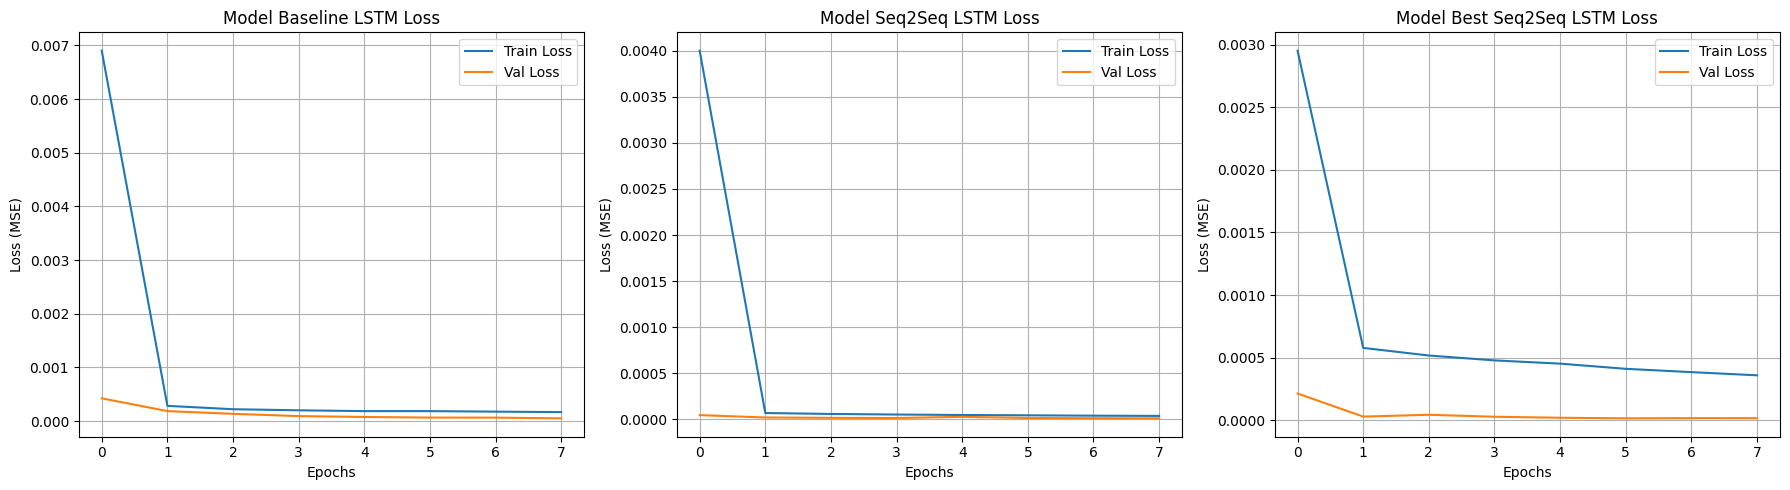

In [10]:
def plot_loss(history, title):
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True)

plt.figure(figsize=(18, 5))

# Baseline
plt.subplot(1, 3, 1)
plot_loss(history_baseline, 'Model Baseline LSTM Loss')

# Seq2Seq
plt.subplot(1, 3, 2)
plot_loss(history_seq2seq, 'Model Seq2Seq LSTM Loss')

# Best Seq2Seq
plt.subplot(1, 3, 3)
plot_loss(history_best, 'Model Best Seq2Seq LSTM Loss')

plt.tight_layout()
plt.savefig('accuracy_loss_plot.png')
plt.show()

Melakukan prediksi pada Test Set...

  1/165 ━━━━━━━━━━━━━━━━━━━━ 15s 93ms/step


 33/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


 63/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


 92/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


122/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


151/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step



Hasil Evaluasi Harga Aktual Bitcoin (USDT):
 - Baseline LSTM   : MAE = 360.25 USDT, RMSE = 495.04 USDT
 - Seq2Seq LSTM    : MAE = 325.43 USDT, RMSE = 462.72 USDT (Autoregressive)
 - Best Seq2Seq LSTM: MAE = 14736.61 USDT, RMSE = 15253.24 USDT (Autoregressive)

Tabel Perbandingan Aktual vs Prediksi 24 Langkah (Sampel Indeks 10):


,Langkah (Hour t+i),Harga Aktual (USDT),Prediksi Baseline LSTM (USDT),Prediksi Seq2Seq LSTM (USDT)
0,t+1,24085.04,23902.083984,24231.841797
1,t+2,24201.15,25048.109375,24402.904297
2,t+3,24113.48,24547.806641,24549.902344
3,t+4,24166.31,24897.953125,24673.658203
4,t+5,24402.53,25569.466797,24772.044922
5,t+6,24274.69,24062.158203,24846.896484
6,t+7,24374.20,23849.433594,24901.509766
7,t+8,24414.06,24325.562500,24939.250000
8,t+9,24317.80,24972.164062,24963.134766
9,t+10,24325.38,24671.255859,24975.730469


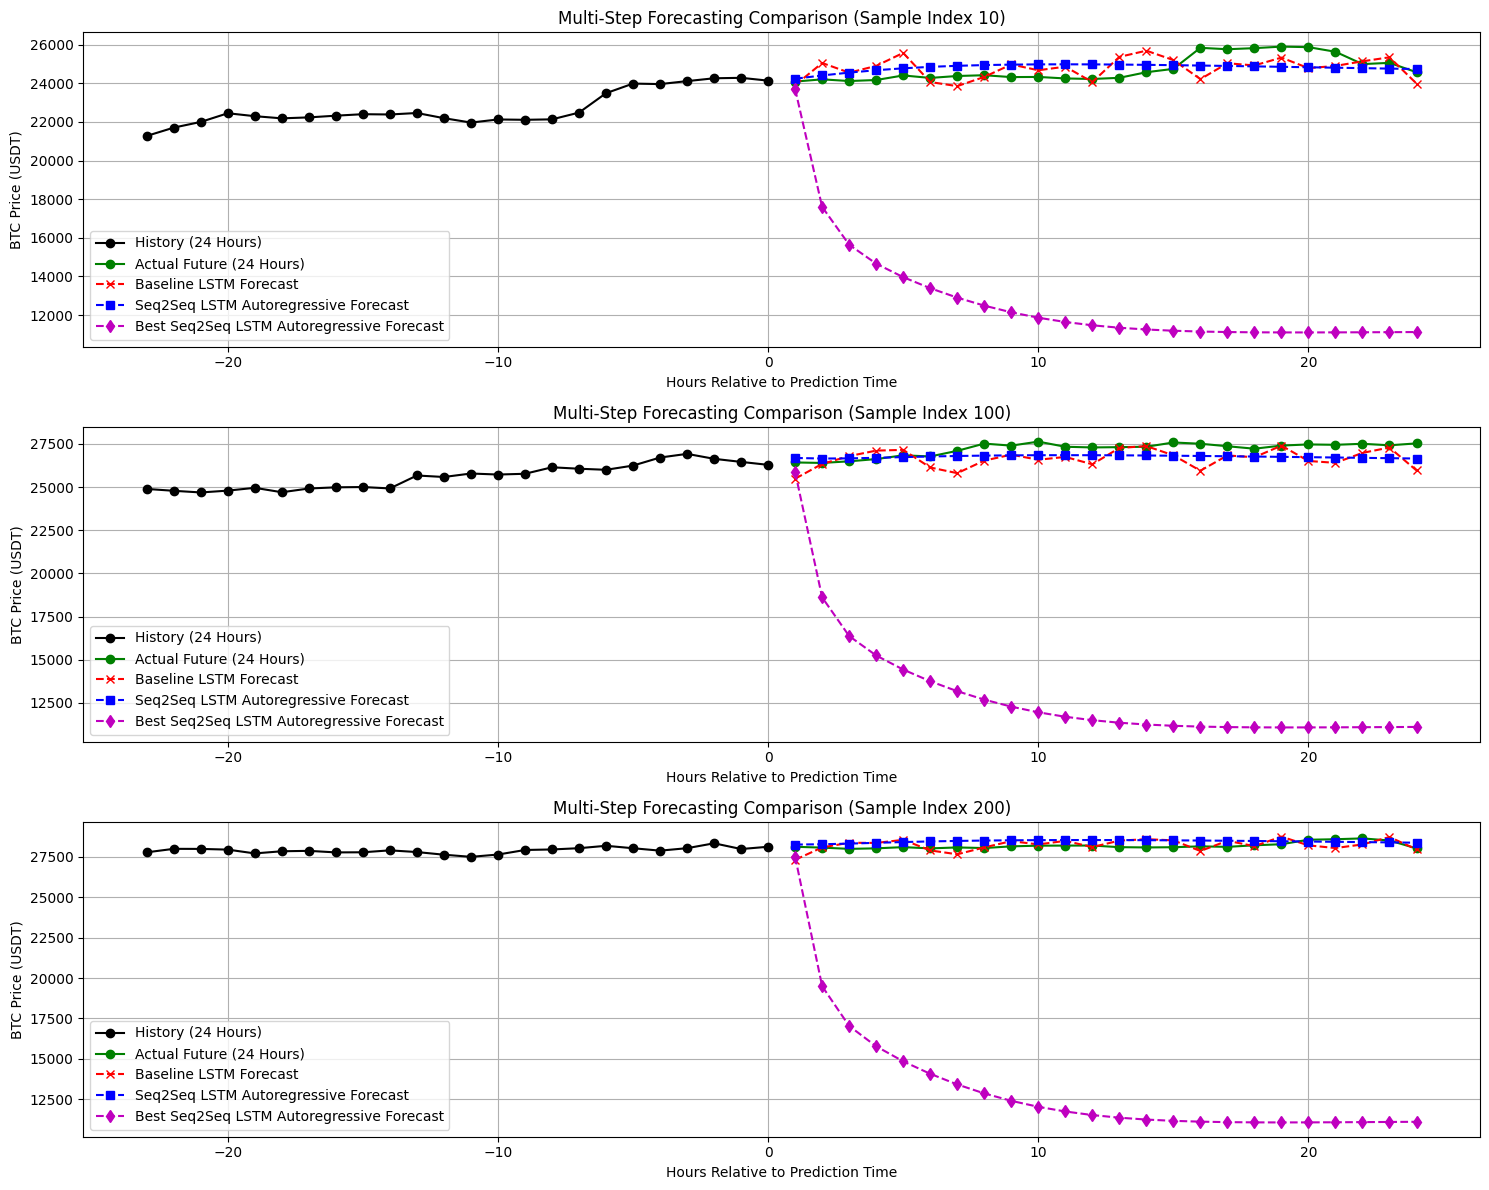

In [11]:
# Fungsi Inferensi Autoregresif untuk Model Seq2Seq (Kriteria 3)
def predict_autoregressive(model, encoder_model, X_input, seq_len=24, horizon=24):
    batch_size = X_input.shape[0]

    # Mendapatkan status awal menggunakan model encoder yang dibagikan secara aman
    state_h_val, state_c_val = encoder_model(X_input, training=False)
    states_value = [state_h_val, state_c_val]

    if 'best' in model.name:
        # Layer decoder
        decoder_lstm1 = model.get_layer('decoder_lstm_best_1')
        decoder_lstm2 = model.get_layer('decoder_lstm_best_2')
        # Mengambil custom dense dari layer pembungkus TimeDistributed
        time_dist = model.get_layer('time_distributed_out_best')
        custom_dense = time_dist.layer

        # Input awal: harga Close terakhir pada input sequence (kolom indeks 0)
        dec_input = tf.expand_dims(X_input[:, -1, 0:1], axis=1)

        predictions = []
        for t in range(horizon):
            x_dec, next_h1, next_c1 = decoder_lstm1(dec_input, initial_state=states_value)
            x_dec_2, _, _ = decoder_lstm2(x_dec)
            pred = custom_dense(x_dec_2)
            predictions.append(pred)

            # Update untuk langkah berikutnya
            dec_input = pred
            states_value = [next_h1, next_c1]

        predictions = tf.concat(predictions, axis=1)
        return predictions.numpy()
    else:
        # Standard Seq2Seq
        decoder_lstm = model.get_layer('decoder_lstm')
        # Mengambil custom dense dari layer pembungkus TimeDistributed
        time_dist = model.get_layer('time_distributed_out')
        custom_dense = time_dist.layer

        dec_input = tf.expand_dims(X_input[:, -1, 0:1], axis=1)

        predictions = []
        for t in range(horizon):
            dec_out, next_h, next_c = decoder_lstm(dec_input, initial_state=states_value)
            pred = custom_dense(dec_out)
            predictions.append(pred)

            # Update untuk langkah berikutnya
            dec_input = pred
            states_value = [next_h, next_c]

        predictions = tf.concat(predictions, axis=1)
        return predictions.numpy()

# Evaluasi pada Test Set
print('Melakukan prediksi pada Test Set...')
pred_b = model_baseline.predict(X_test)
# Menggunakan inferensi autoregresif untuk model Seq2Seq
pred_s = predict_autoregressive(model_seq2seq, encoder_model_seq2seq, X_test)
pred_best = predict_autoregressive(model_best, encoder_model_best, X_test)

# Mengembalikan nilai scaling target (Close price) ke harga aktual
num_test_samples = len(y_test)
y_test_flat = y_test.reshape(-1, 1)
y_test_actual = target_scaler.inverse_transform(y_test_flat).reshape(num_test_samples, horizon)

pred_b_actual = target_scaler.inverse_transform(pred_b.reshape(-1, 1)).reshape(num_test_samples, horizon)
pred_s_actual = target_scaler.inverse_transform(pred_s.reshape(-1, 1)).reshape(num_test_samples, horizon)
pred_best_actual = target_scaler.inverse_transform(pred_best.reshape(-1, 1)).reshape(num_test_samples, horizon)

# Menghitung MAE dan RMSE pada harga aktual
from sklearn.metrics import mean_absolute_error, mean_squared_error

def compute_metrics(actual, pred):
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    return mae, rmse

mae_b_act, rmse_b_act = compute_metrics(y_test_actual, pred_b_actual)
mae_s_act, rmse_s_act = compute_metrics(y_test_actual, pred_s_actual)
mae_best_act, rmse_best_act = compute_metrics(y_test_actual, pred_best_actual)

print('\nHasil Evaluasi Harga Aktual Bitcoin (USDT):')
print(f' - Baseline LSTM   : MAE = {mae_b_act:.2f} USDT, RMSE = {rmse_b_act:.2f} USDT')
print(f' - Seq2Seq LSTM    : MAE = {mae_s_act:.2f} USDT, RMSE = {rmse_s_act:.2f} USDT (Autoregressive)')
print(f' - Best Seq2Seq LSTM: MAE = {mae_best_act:.2f} USDT, RMSE = {rmse_best_act:.2f} USDT (Autoregressive)')

# Membuat Tabel Perbandingan Aktual vs Prediksi untuk 24 Langkah (Kriteria 3)
sample_idx = 10
actual_sample = y_test_actual[sample_idx]
pred_b_sample = pred_b_actual[sample_idx]
pred_s_sample = pred_s_actual[sample_idx]

comparison_df = pd.DataFrame({
    'Langkah (Hour t+i)': [f't+{i}' for i in range(1, horizon + 1)],
    'Harga Aktual (USDT)': actual_sample,
    'Prediksi Baseline LSTM (USDT)': pred_b_sample,
    'Prediksi Seq2Seq LSTM (USDT)': pred_s_sample
})

print(f'\nTabel Perbandingan Aktual vs Prediksi 24 Langkah (Sampel Indeks {sample_idx}):')
try:
    from IPython.display import display
    display(comparison_df)
except ImportError:
    print(comparison_df.to_string(index=False))

# Plot perbandingan prediksi vs aktual untuk 3 sampel acak
sample_indices = [10, 100, 200]
plt.figure(figsize=(15, 12))

for idx, sample_idx_plot in enumerate(sample_indices):
    plt.subplot(3, 1, idx + 1)
    
    # 24 jam ke belakang (input history)
    history_actual = target_scaler.inverse_transform(X_test[sample_idx_plot, :, 0].reshape(-1, 1)).flatten()
    
    # 24 jam ke depan (prediksi dan aktual)
    actual_future = y_test_actual[sample_idx_plot]
    predicted_b = pred_b_actual[sample_idx_plot]
    predicted_s = pred_s_actual[sample_idx_plot]
    predicted_best = pred_best_actual[sample_idx_plot]
    
    # Tumbu X untuk plotting
    x_history = np.arange(-seq_len + 1, 1)
    x_future = np.arange(1, horizon + 1)
    
    plt.plot(x_history, history_actual, 'k-o', label='History (24 Hours)')
    plt.plot(x_future, actual_future, 'g-o', label='Actual Future (24 Hours)')
    plt.plot(x_future, predicted_b, 'r--x', label='Baseline LSTM Forecast')
    plt.plot(x_future, predicted_s, 'b--s', label='Seq2Seq LSTM Autoregressive Forecast')
    plt.plot(x_future, predicted_best, 'm--d', label='Best Seq2Seq LSTM Autoregressive Forecast')
    
    plt.title(f'Multi-Step Forecasting Comparison (Sample Index {sample_idx_plot})')
    plt.xlabel('Hours Relative to Prediction Time')
    plt.ylabel('BTC Price (USDT)')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.savefig('predictions_vs_actual_plot.png')
plt.show()